# MetricSuite 3 -- Choosing and reading a test

A test answers one question: *is the difference between two methods larger than
chance would produce?* Getting the answer right depends less on the test's name than
on three choices made before it:

- **Part 1 -- the unit.** What is one independent observation? (the most common
  mistake);
- **Part 2 -- paired or independent?**
- **Part 3 -- rank-based or t-test?** And what to do with autocorrelated units;
- **Part 4 -- three methods or more**: omnibus test, all pairs, multiple-comparison
  corrections;
- **Part 5 -- reading and drawing a result**: `vs()`, and the stat plots.

| test | design | assumes |
|---|---|---|
| `wilcoxon` | paired | symmetric differences (no normality) |
| `paired_ttest` | paired | roughly normal differences |
| `ttest_ess` | paired, ordered units (time, channels) | normal differences, autocorrelation corrected |
| `mannwhitneyu` | independent | -- |
| `ttest` | independent | roughly normal groups (Welch) |
| `mcnemar` | paired, 0/1 outcome | -- (tutorial 5) |
| `bootstrap` | either, any estimator | independent units (tutorial 6) |
| `anova` | 3+ paired groups | Friedman (ranks) or repeated-measures ANOVA |
| `cluster_permutation` | paired curves | -- (tutorial 7) |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

from mindmap.metric import MetricSuite

COLORS = {"wCSET": "#2a78d6", "CSET": "#1baf7a", "dSPM": "#e34948", "sLORETA": "#f0a020"}

## 🧱 - Part 1: What is one observation?

Tests assume independent observations. When a patient is simulated 10 times, those
10 runs are **not** 10 independent patients: they share the patient's anatomy, and
-- crucially -- they share how much *this patient* favours one method over the other.

The fake study below has a real but small average advantage for `wCSET` (1 mm), and
patients disagree a lot about it (some favour `CSET` by 3 mm, others `wCSET` by 5).
Each patient is simulated 10 times with little run-to-run noise.

In [2]:
rng = np.random.default_rng(11)
runs = MetricSuite(name="Runs")
for p in range(8):
    patient = f"P{p}"
    base = rng.normal(20, 4)
    advantage = rng.normal(1.0, 3.0)               # how much THIS patient favours wCSET
    for run in range(10):
        runs.register("loc_error_mm", base + rng.normal(0, 1), method="CSET", patient=patient, run=run,
                      sim=f"{patient}-{run}")
        runs.register("loc_error_mm", base - advantage + rng.normal(0, 1), method="wCSET", patient=patient,
                      run=run, sim=f"{patient}-{run}")

Two ways to pair the methods:

- **wrong**: pair every simulation (`pairing_col="sim"`) -- 80 "independent" pairs;
- **right**: pair patients (`pairing_col="patient"`), averaging each patient's runs
  first (`unit_col="run"`) -- 8 pairs.

In [3]:
pairs = [("wCSET", "CSET")]
wrong = runs.stat.wilcoxon("loc_error_mm", "method", pairs, pairing_col="sim")
right = runs.stat.wilcoxon("loc_error_mm", "method", pairs, pairing_col="patient", unit_col="run")
print(wrong)
print(right)

PairwiseResult(metric='loc_error_mm', test='wilcoxon', correction='fdr_bh', alpha=0.05, n_comparisons=1)
  wCSET vs CSET: p=4.431e-06*, rank_biserial=-0.591 [-0.76, -0.387], n=80
PairwiseResult(metric='loc_error_mm', test='wilcoxon', correction='fdr_bh', alpha=0.05, n_comparisons=1)
  wCSET vs CSET: p=0.25, rank_biserial=-0.5 [-0.944, 0.389], n=8


The wrong analysis is "highly significant" with n = 80; the right one isn't, with
n = 8. The 10 runs only measure each patient's advantage more precisely -- they say
nothing about *other* patients, which is what the claim is about. Pseudo-replication
like this produces confident p-values for effects that don't generalize.

**Rule:** the pairing unit is the level at which the effect really varies -- the
patient (or subject, or region across subjects), not the finest grain the data
happen to have. Use `unit_col` for repeated measurements within that unit.

The plots honour the same collapsing: `unit` in the data plots, and the result's own
`pairing_col`/`unit_col` in the stat plots.

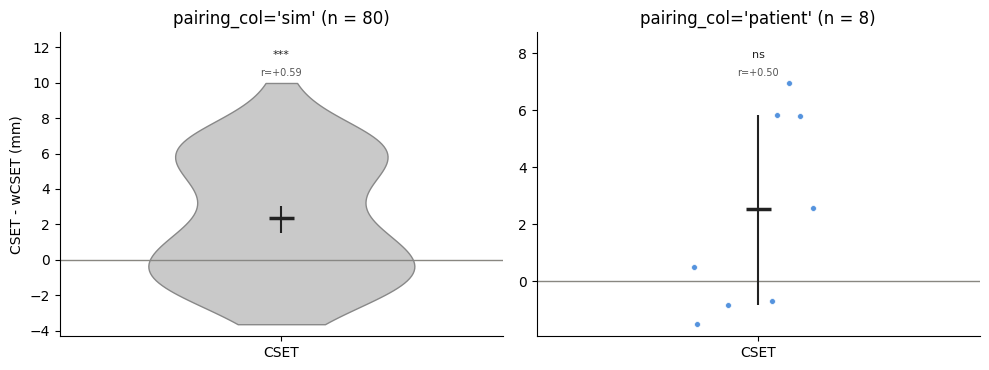

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
runs.plot.paired_differences(wrong, higher_is_better=False, ax=axes[0], title="pairing_col='sim' (n = 80)",
                             palette=["#888888"], ylabel="CSET - wCSET (mm)")
runs.plot.paired_differences(right, higher_is_better=False, ax=axes[1], title="pairing_col='patient' (n = 8)",
                             palette=["#2a78d6"], ylabel="")
fig.tight_layout()

## 🔗 - Part 2: Paired or independent?

When every patient is measured with every method, compare methods **within**
patients. Here is a study with 20 patients and 4 methods, one error per patient and
method. Patients differ a lot in difficulty (± 6 mm), much more than methods differ,
and every method occasionally misses badly (+15 mm in 12% of cases).

In [5]:
TRUE_ERROR = {"wCSET": 14.0, "CSET": 15.5, "dSPM": 19.0, "sLORETA": 18.5}
rng = np.random.default_rng(7)
suite = MetricSuite(name="Four methods")
for p in range(20):
    difficulty = rng.normal(0, 6)
    for method, mu in TRUE_ERROR.items():
        miss = 15.0 * (rng.random() < 0.12)                   # an occasional large miss
        suite.register("loc_error_mm", max(mu + difficulty + rng.normal(0, 1.2) + miss, 1.0),
                       method=method, patient=f"P{p:02d}")

The independent test (`mannwhitneyu`) compares the two clouds of 20 values, so the
patient-to-patient spread swamps the 1.5 mm method effect. The paired test
(`wilcoxon`) compares methods inside each patient, where the spread cancels:

In [6]:
pair = [("wCSET", "CSET")]
independent = suite.stat.mannwhitneyu("loc_error_mm", "method", pair)
paired = suite.stat.wilcoxon("loc_error_mm", "method", pair, pairing_col="patient")
independent.table[["group_a", "group_b", "n_a", "n_b", "p_value"]], paired.table[["group_a", "group_b", "n_pairs", "p_value"]]

(  group_a group_b  n_a  n_b   p_value
 0   wCSET    CSET   20   20  0.456866,
   group_a group_b  n_pairs   p_value
 0   wCSET    CSET       20  0.008308)

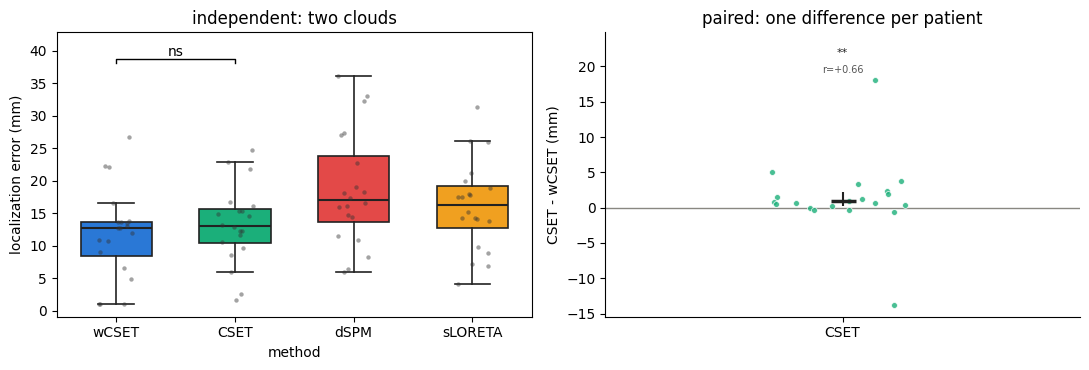

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
suite.plot.group_comparison(independent, palette=COLORS, ax=axes[0], title="independent: two clouds",
                            show_ns=True, ylabel="localization error (mm)")
suite.plot.paired_differences(paired, higher_is_better=False, palette=COLORS, ax=axes[1],
                              title="paired: one difference per patient", ylabel="CSET - wCSET (mm)")
fig.tight_layout()

Use the independent tests only when the groups really are different units (e.g.
two separate patient cohorts). `pairing_col` is required by the paired tests and
refused by the independent ones, so the design is always explicit in the result.

## ⚖️ - Part 3: Rank-based or t-test?

### Look at the differences

A paired test only looks at the differences, so their shape is what matters. Here
the differences are heavy-tailed: most are small, a few are large (a miss by one of
the two methods). The
`normality_test` view checks each method's values; for a paired test, check the
differences themselves -- `suite.stat.paired_differences(result)` returns exactly
the ones the test used:

In [8]:
pairs = suite.stat.build_comparisons("wCSET", ["CSET", "dSPM", "sLORETA"])
wil = suite.stat.wilcoxon("loc_error_mm", "method", pairs, pairing_col="patient", correction="holm")
diffs = suite.stat.paired_differences(wil, higher_is_better=False)
diffs.head()

method,CSET,dSPM,sLORETA
patient,,,
P00,1.283360,5.401138,4.238318
P01,-0.044826,5.406099,3.522597
P02,1.571728,21.780765,3.072552
P03,0.790725,3.893425,3.394988
P04,2.332877,4.230254,6.830909


In [9]:
{c: round(stats.shapiro(diffs[c].dropna()).pvalue, 4) for c in diffs.columns}

{'CSET': np.float64(0.0),
 'dSPM': np.float64(0.0003),
 'sLORETA': np.float64(0.0)}

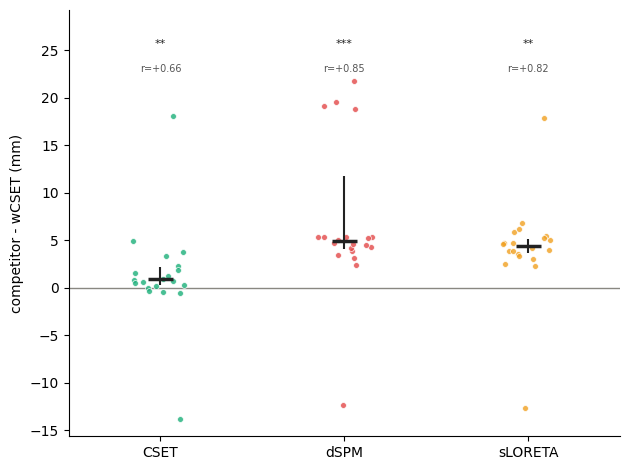

In [10]:
fig, ax = suite.plot.paired_differences(wil, higher_is_better=False, palette=COLORS, kind="strip",
                                        ylabel="competitor - wCSET (mm)")
fig.tight_layout()

### Same data, two tests

The Wilcoxon test works on ranks, so a few large differences count like any other
positive difference. The t-test works on the mean and SD, which the large ones
inflate -- it loses power with heavy tails:

In [11]:
tt = suite.stat.paired_ttest("loc_error_mm", "method", pairs, pairing_col="patient", correction="holm")
wil.vs("wCSET", higher_is_better=False)[["p_corrected"]].join(
    tt.vs("wCSET", higher_is_better=False)[["p_corrected"]], lsuffix="_wilcoxon", rsuffix="_ttest")

,p_corrected_wilcoxon,p_corrected_ttest
method,,
CSET,0.008308,0.291843
dSPM,0.000967,0.003166
sLORETA,0.001171,0.003166


How to choose:

- **Wilcoxon** by default for paired data: no normality assumption, little power
  lost when the data *are* normal. It tests whether differences tend to be
  positive; report it with medians and the Hodges-Lehmann estimate (tutorial 4).
- **Paired t-test** when the differences are close to normal and the *mean* is the
  quantity you care about (e.g. it enters a further calculation).

On these heavy-tailed data the t-test misses `wCSET` vs `CSET` entirely -- Part 5
shows it on a plot.

### Autocorrelated units: `ttest_ess`

Sometimes the units are ordered and correlated -- timepoints of one recording, or
neighbouring channels. Each new timepoint repeats much of the previous one, so 300
timepoints carry far less than 300 independent observations, and an ordinary test is
overconfident. `ttest_ess` replaces n by the *effective sample size* computed from
the differences' autocorrelation (`n_eff`). It needs the true order of the units:
`subject_order`.

In [12]:
rng = np.random.default_rng(1)
n_t, rho = 300, 0.9
noise = np.zeros(n_t)
for i in range(1, n_t):
    noise[i] = rho * noise[i - 1] + rng.normal(0, 1)
times = np.arange(n_t)
series = MetricSuite(name="One recording")
series.register("amplitude", rng.normal(0, 0.1, n_t), method="dSPM", t=times)
series.register("amplitude", 0.4 + noise, method="wCSET", t=times)

plain = series.stat.paired_ttest("amplitude", "method", [("wCSET", "dSPM")], pairing_col="t")
ess = series.stat.ttest_ess("amplitude", "method", [("wCSET", "dSPM")], pairing_col="t",
                            subject_order=list(times))
plain.table[["n_pairs", "p_value"]].assign(test="paired_ttest"), ess.table[["n_pairs", "n_eff", "p_value"]].assign(test="ttest_ess")

(   n_pairs       p_value          test
 0      300  1.094906e-13  paired_ttest,
    n_pairs      n_eff   p_value       test
 0      300  17.902649  0.074139  ttest_ess)

300 timepoints are worth about `n_eff` independent ones; the p-value grows
accordingly. Even so, a test across the timepoints of **one** recording only speaks
about that recording -- to generalize, test across recordings or patients (Part 1).

## 🔢 - Part 4: Three methods or more

### Omnibus first

With several methods, `anova` asks one question first: *do the methods differ at
all?* `test="friedman"` (default) is the rank-based version, `test="anova"` the
repeated-measures ANOVA. Both are paired on `pairing_col`.

In [13]:
omnibus = suite.stat.anova("loc_error_mm", "method", pairing_col="patient")
omnibus

AnovaResult(metric='loc_error_mm', test='friedman', groups=('CSET', 'dSPM', 'sLORETA', 'wCSET')): p=1.787e-08*, kendalls_w=0.649, n=20, k=4

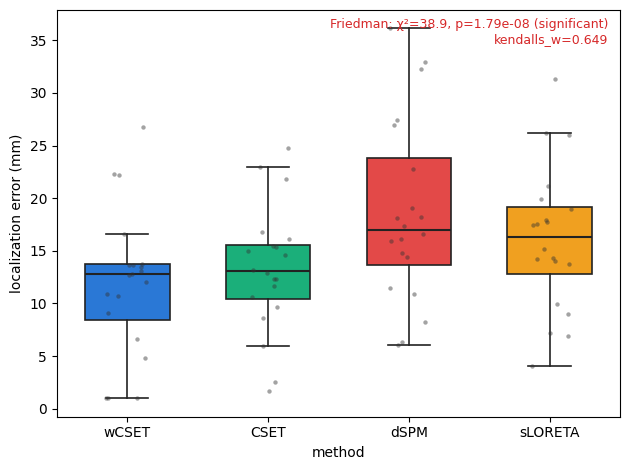

In [14]:
fig, ax = suite.plot.anova(omnibus, order=list(TRUE_ERROR), palette=COLORS, ylabel="localization error (mm)")
fig.tight_layout()

### Then the pairs you care about

`build_comparisons(references, competitors)` builds the pairs. One reference
against everything is the usual case; a list on both sides gives every pair (each
once):

In [15]:
suite.stat.build_comparisons(["wCSET", "CSET"], ["CSET", "dSPM", "sLORETA"])

[('wCSET', 'CSET'),
 ('wCSET', 'dSPM'),
 ('wCSET', 'sLORETA'),
 ('CSET', 'dSPM'),
 ('CSET', 'sLORETA')]

In [16]:
methods = list(TRUE_ERROR)
all_pairs = suite.stat.build_comparisons(methods, methods)
every = suite.stat.wilcoxon("loc_error_mm", "method", all_pairs, pairing_col="patient")
every

PairwiseResult(metric='loc_error_mm', test='wilcoxon', correction='fdr_bh', alpha=0.05, n_comparisons=6)
  wCSET vs CSET: p=0.00997*, rank_biserial=-0.657 [-0.952, -0.238], n=20
  wCSET vs dSPM: p=0.0008783*, rank_biserial=-0.848 [-1, -0.514], n=20
  wCSET vs sLORETA: p=0.0008783*, rank_biserial=-0.819 [-1, -0.457], n=20
  CSET vs dSPM: p=0.0008783*, rank_biserial=-0.829 [-1, -0.495], n=20
  CSET vs sLORETA: p=0.0008783*, rank_biserial=-0.819 [-1, -0.457], n=20
  dSPM vs sLORETA: p=0.2611, rank_biserial=0.295 [-0.2, 0.743], n=20

### Multiple-comparison corrections

Six tests at alpha = 0.05 make a false positive likely somewhere. `correction`
adjusts the p-values across every pair in the result (one *family*):

- `"fdr_bh"` (default): controls the expected share of false discoveries -- good for
  screening many comparisons;
- `"holm"`: controls the chance of *any* false positive (family-wise error), and is
  always at least as powerful as Bonferroni -- the usual choice for a few planned
  comparisons in a paper;
- `"bonferroni"`: the simplest family-wise control, the most conservative;
- `"fdr_by"`: FDR under arbitrary dependence.

`result.correct(...)` re-corrects an existing result without rerunning the tests:

In [17]:
corrections = {m: every.correct(m).table["p_corrected"].round(4) for m in ["fdr_bh", "holm", "bonferroni"]}
every.table[["group_a", "group_b", "p_value"]].round(4).assign(**corrections)

,group_a,group_b,p_value,fdr_bh,holm,bonferroni
0,wCSET,CSET,0.0083,0.0100,0.0166,0.0499
1,wCSET,dSPM,0.0003,0.0009,0.0019,0.0019
2,wCSET,sLORETA,0.0006,0.0009,0.0024,0.0035
3,CSET,dSPM,0.0005,0.0009,0.0024,0.0029
4,CSET,sLORETA,0.0006,0.0009,0.0024,0.0035
5,dSPM,sLORETA,0.2611,0.2611,0.2611,1.0000


The family is whatever you put in one call. Plan it: e.g. "wCSET vs each competitor,
Holm across the 3" is one call; a second outcome measure is a separate call and a
separate family.

## 📖 - Part 5: Reading and drawing a result

### `vs(reference)`

`vs` gives one row per competitor of `reference`, oriented so that **positive means
the reference is better** -- whichever order the pair was stored in. For an error,
pass `higher_is_better=False`:

In [18]:
wil.vs("wCSET", higher_is_better=False)

,p_value,p_corrected,significant,rank_biserial,rank_biserial_ci_low,rank_biserial_ci_high,offset,alternative,n_pairs,n_zero
method,,,,,,,,,,
CSET,0.008308,0.008308,True,0.657143,0.238095,0.952381,0.0,two-sided,20,0
dSPM,0.000322,0.000967,True,0.847619,0.514286,1.000000,0.0,two-sided,20,0
sLORETA,0.000586,0.001171,True,0.819048,0.457143,1.000000,0.0,two-sided,20,0


### Stat plots and `center="auto"`

Stat plots take a result and draw what it tested, with the same rows and the same
collapsing. Their summary defaults to `center="auto"`, which matches the test:

| test | auto center |
|---|---|
| `wilcoxon`, `mannwhitneyu`, `friedman` | median (+ exact CI) |
| `paired_ttest`, `ttest`, `ttest_ess`, `anova` | mean (+ t CI) |
| `mcnemar` | proportion (+ Wilson CI) |

On a box (already median + IQR) "auto" adds nothing. `kind` picks the element. Note
the missing `CSET` bracket on the t-test (right): the heavy tails cost it the
comparison the Wilcoxon test finds.

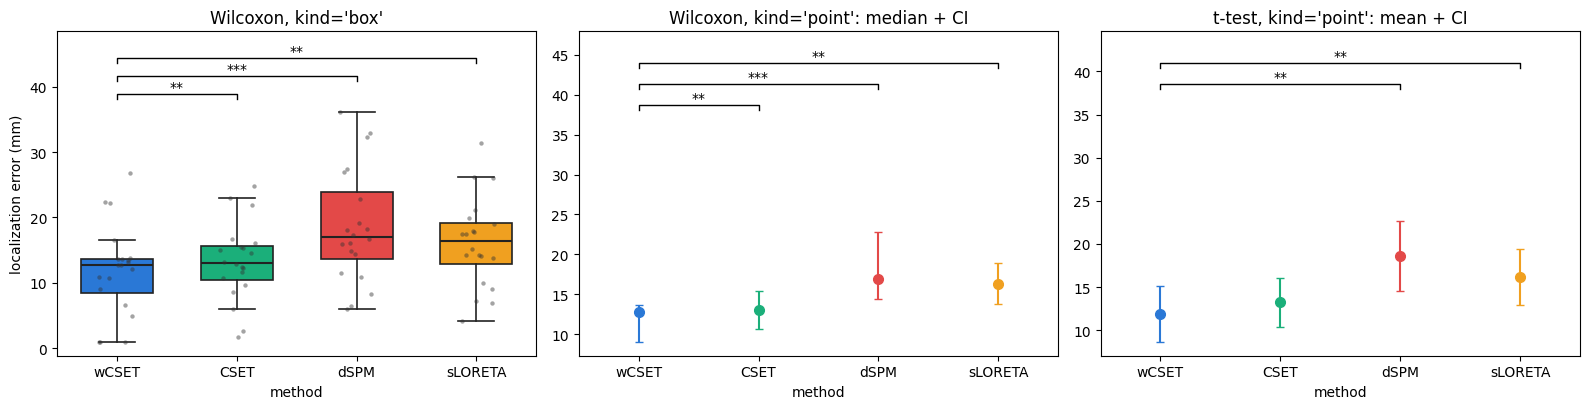

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
order = ["wCSET", "CSET", "dSPM", "sLORETA"]
suite.plot.group_comparison(wil, order=order, palette=COLORS, ax=axes[0], title="Wilcoxon, kind='box'",
                            ylabel="localization error (mm)")
suite.plot.group_comparison(wil, kind="point", order=order, palette=COLORS, ax=axes[1],
                            title="Wilcoxon, kind='point': median + CI", ylabel="")
suite.plot.group_comparison(tt, kind="point", order=order, palette=COLORS, ax=axes[2],
                            title="t-test, kind='point': mean + CI", ylabel="")
fig.tight_layout()

### What the brackets say

`annotate` chooses the bracket text: `"stars"`, `"p"`, `"effect"` (the result's
first effect size), any effect size the result holds, `"n_eff"`. `show_ns=True`
also draws the non-significant pairs. `reference_lines` adds labelled guides.
`higher_is_better=False` orients the effect sizes like `vs()`: positive = the
reference is better.

Brackets always go from one `reference` to its competitors. It's inferred when every
pair shares a group; for an all-pairs result, say which one to draw:

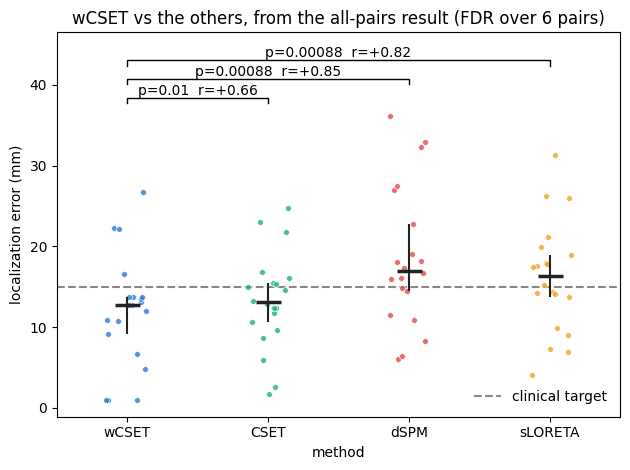

In [20]:
fig, ax = suite.plot.group_comparison(
    every, kind="strip", reference="wCSET", higher_is_better=False, order=order, palette=COLORS,
    annotate=("p", "effect"), show_ns=True,
    reference_lines={"clinical target": 15}, ylabel="localization error (mm)",
    title="wCSET vs the others, from the all-pairs result (FDR over 6 pairs)",
)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()

## Wrap-up

1. **Unit first**: pair on the level where the effect varies (patients), and
   average repeated measurements with `unit_col`. More rows is not more evidence.
2. **Paired when you can**: within-patient comparisons remove the patient-to-patient
   spread.
3. **Wilcoxon by default** for paired data; t-tests when differences are near
   normal and the mean matters; `ttest_ess` for autocorrelated, ordered units.
4. **Several methods**: `anova` for the omnibus question, then planned pairs with
   `build_comparisons`, corrected as one family (`"holm"` for a handful of
   planned comparisons).
5. `vs()` reads a result with "positive = reference better"; the stat plots draw
   it with the summary that matches the test.

Next: **tutorial 4** -- how large is the difference?